## Orthogonal Basis: Key Properties

- **Orthogonality:**
  - For functions $\psi_i(x)$ and $\psi_j(x)$ in an orthogonal basis:
    $$
    \langle \psi_i, \psi_j \rangle = \int \psi_i(x)\,\psi_j(x)\,dx = 0 \quad \text{for } i \neq j
    $$
    (The inner product of different modes is zero.)
- **Norm:**
  - For each basis function:
    $$
    \langle \psi_i, \psi_i \rangle = \int |\psi_i(x)|^2 dx > 0
    $$
    (The inner product with itself is positive.)
- **Orthonormality:**
  - If the basis is also normalized:
    $$
    \langle \psi_i, \psi_j \rangle = \delta_{ij}
    $$
    (Kronecker delta: 1 if $i=j$, 0 otherwise.)
- **Expansion:**
  - Any function $f(x)$ in the space can be written as:
    $$
    f(x) = \sum_i c_i\,\psi_i(x)
    $$
    where $c_i = \langle f, \psi_i \rangle / \langle \psi_i, \psi_i \rangle$

**In this notebook:**
- The Haar wavelets $f_{10}$, $f_{21}$, $f_{22}$ are orthogonal: their integrals of products are zero for different wavelets, and positive for themselves.
- This property is fundamental for building efficient, non-redundant signal representations.

# Exploring Haar Wavelets and Orthogonality

This notebook demonstrates the construction and properties of simple Haar-like wavelets:

- **Wavelet construction:**
  - `f10`, `f21`, `f22` are piecewise-constant functions (Haar wavelets) defined on a grid.
  - Each is zero-mean (integral is zero) and localized in different regions.
- **Orthogonality:**
  - The product of two different wavelets, integrated over the domain, is zero (they are orthogonal).
  - The product of a wavelet with itself, integrated, is positive (its norm squared).
- **Linear combinations:**
  - Any linear combination of these wavelets is also zero-mean.
- **Fourier analysis:**
  - The notebook also shows the Fourier coefficients of each wavelet, connecting wavelet and Fourier perspectives.

These properties are fundamental to wavelet analysis: wavelets are localized, zero-mean, and form an orthogonal basis for representing signals.

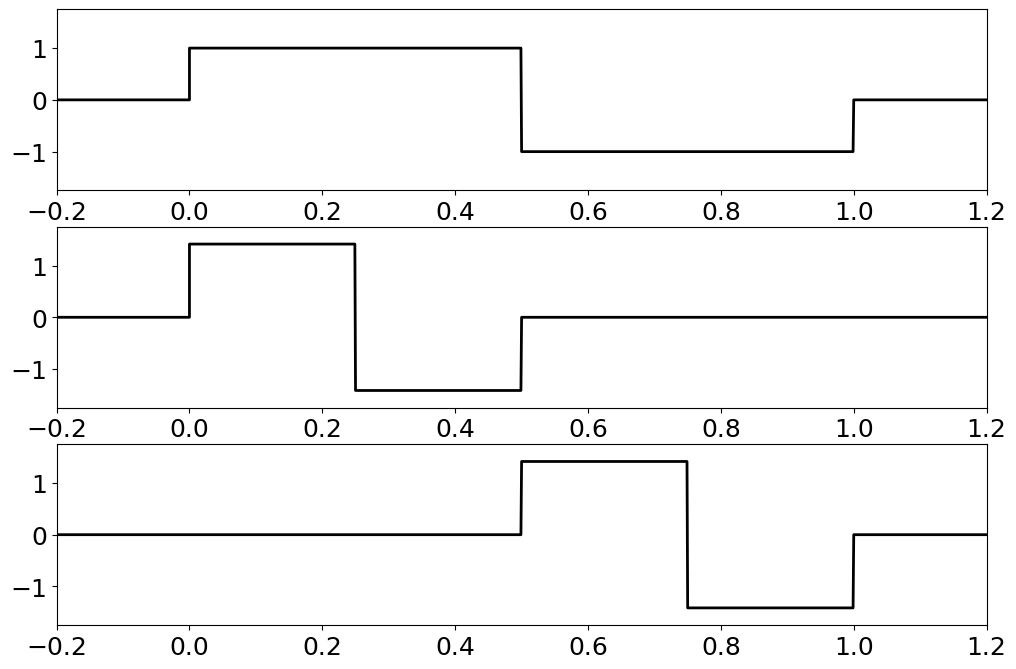

In [4]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [12, 8]
plt.rcParams.update({'font.size': 18})

# Always start from the original x and build all arrays from scratch
x_base = np.arange(0,1,0.001)
n = len(x_base)
n2 = int(np.floor(n/2))
n4 = int(np.floor(n/4))

f10 = np.zeros_like(x_base)
f10[:n2] = 1
f10[n2:] = -1

f21 = np.zeros_like(x_base)
f21[:n4] = 1
f21[n4:n2] = -1
f21 = f21 * np.sqrt(2)

f22 = np.zeros_like(x_base)
f22[n2:(n2+n4)] = 1
f22[(n2+n4):] = -1
f22 = f22 * np.sqrt(2)

# Pad x and wavelets identically
x_pad = np.concatenate(([-1,0], x_base, [1,2]))
f10_pad = np.pad(f10, (2, 2), 'constant')
f21_pad = np.pad(f21, (2, 2), 'constant')
f22_pad = np.pad(f22, (2, 2), 'constant')

fig,axs = plt.subplots(3,1)
axs[0].plot(x_pad, f10_pad, color='k', linewidth=2)
axs[0].set_xlim(-0.2,1.2)
axs[0].set_ylim(-1.75,1.75)
axs[1].plot(x_pad, f21_pad, color='k', linewidth=2)
axs[1].set_xlim(-0.2,1.2)
axs[1].set_ylim(-1.75,1.75)
axs[2].plot(x_pad, f22_pad, color='k', linewidth=2)
axs[2].set_xlim(-0.2,1.2)
axs[2].set_ylim(-1.75,1.75)
plt.show()

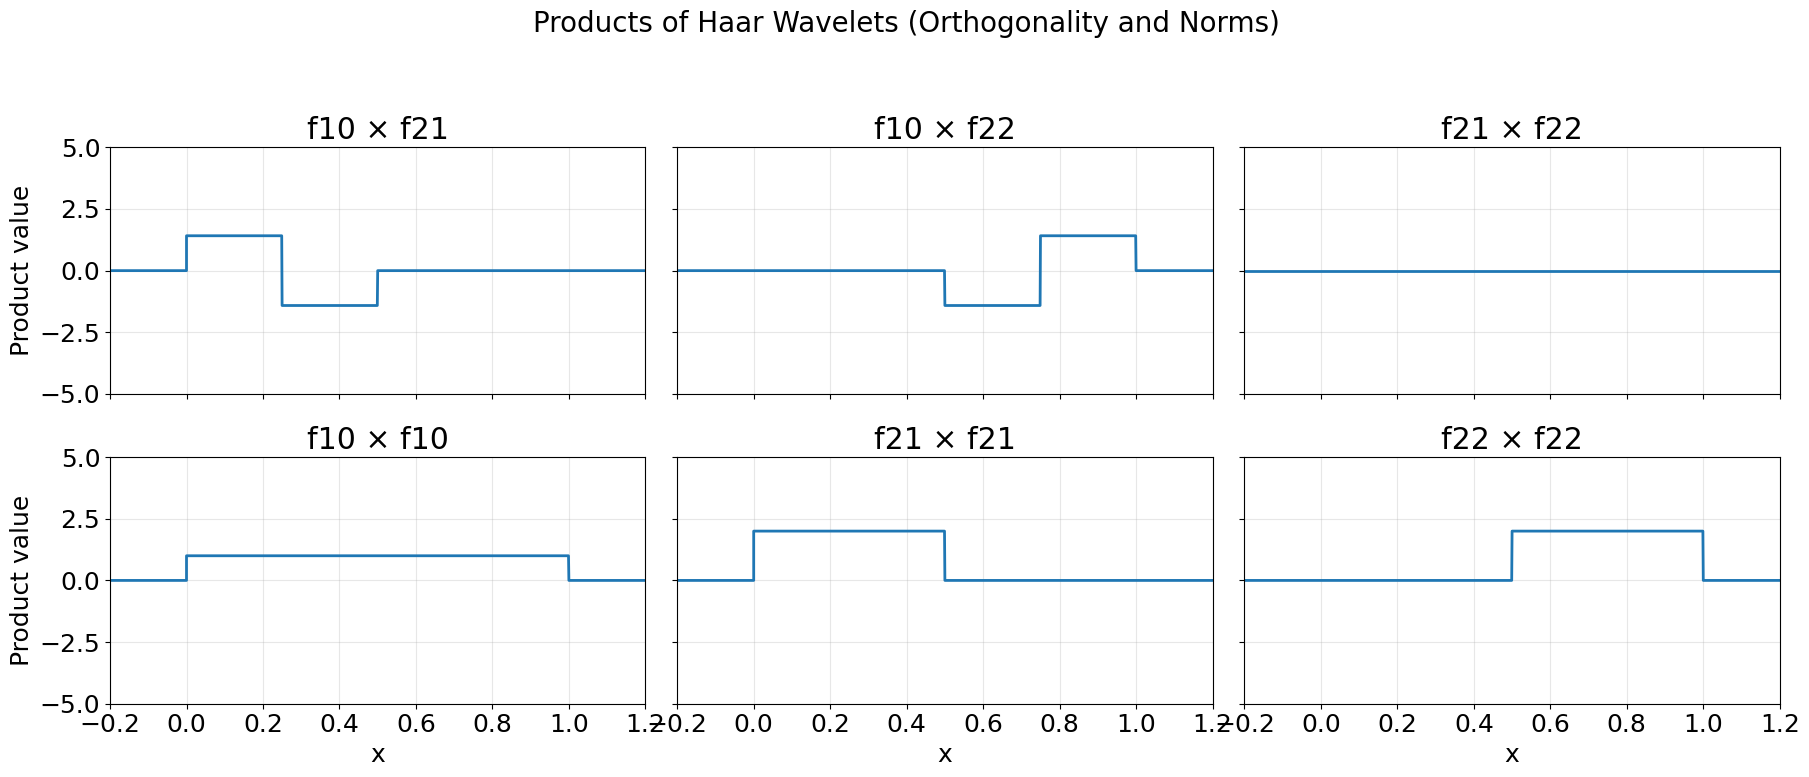

In [ ]:
# Plot all pairwise products and self-products in separate subplots (same figure)

products = [
	(f10_pad * f21_pad, 'f10 x f21'),
	(f10_pad * f22_pad, 'f10 x f22'),
	(f21_pad * f22_pad, 'f21 x f22'),
	(f10_pad * f10_pad, 'f10 x f10'),
	(f21_pad * f21_pad, 'f21 x f21'),
	(f22_pad * f22_pad, 'f22 x f22'),
]

fig, axs = plt.subplots(2, 3, figsize=(18, 8), sharex=True, sharey=True)

for ax, (prod, label) in zip(axs.flat, products):
	ax.plot(x_pad, prod, linewidth=2)
	ax.set_title(label)
	ax.grid(True, alpha=0.3)
	ax.set_xlim(-0.2, 1.2)
	ax.set_ylim(-5, 5)

fig.suptitle('Products of Haar Wavelets (Orthogonality and Norms)', fontsize=20)

for ax in axs[-1,:]:
	ax.set_xlabel('x')

for ax in axs[:,0]:
	ax.set_ylabel('Product value')

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.show()

## Fourier Analysis of Haar Mode 1 ($f_{10}$)

We analyze the frequency content of the first Haar wavelet ($f_{10}$) by computing its discrete Fourier transform (DFT). This reveals which frequencies are present in this mode.

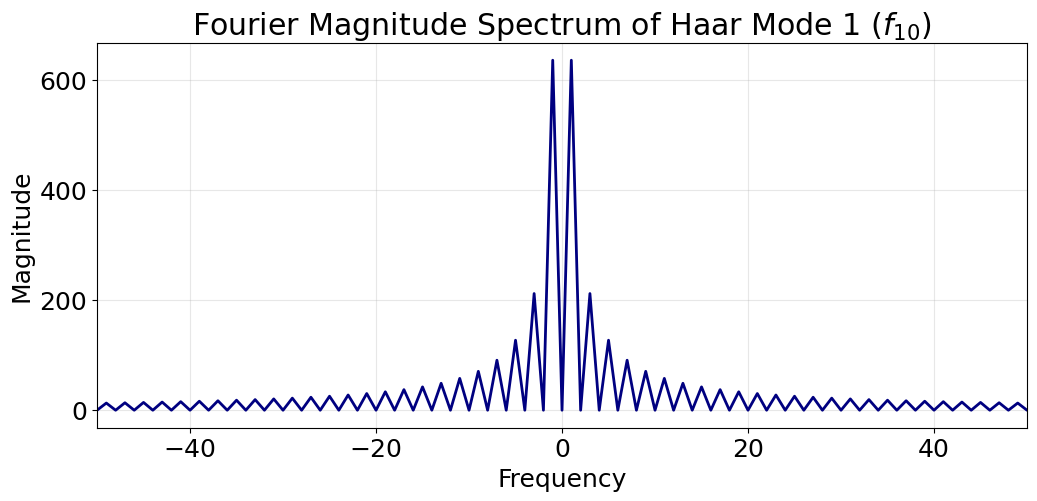

In [25]:
# Compute and plot the Fourier transform of Haar mode 1 (f10)
from numpy.fft import fft, fftfreq, fftshift

# Use the unpadded f10 and x_base for DFT
N = len(x_base)
dx = x_base[1] - x_base[0]
F_f10 = fft(f10)
freqs = fftfreq(N, d=dx)

# Shift zero frequency to center for visualization
F_f10_shifted = fftshift(F_f10)
freqs_shifted = fftshift(freqs)

plt.figure(figsize=(12,5))
plt.plot(freqs_shifted, np.abs(F_f10_shifted), color='navy', linewidth=2)
plt.title('Fourier Magnitude Spectrum of Haar Mode 1 ($f_{10}$)')
plt.xlabel('Frequency')
plt.ylabel('Magnitude')
plt.grid(True, alpha=0.3)
plt.xlim(-50, 50)
plt.show()

## Fourier Analysis of Haar Mode 2 ($f_{21}$)

Now we analyze the frequency content of the second Haar wavelet ($f_{21}$) by computing its discrete Fourier transform (DFT). This shows which frequencies are present in this higher-frequency mode.

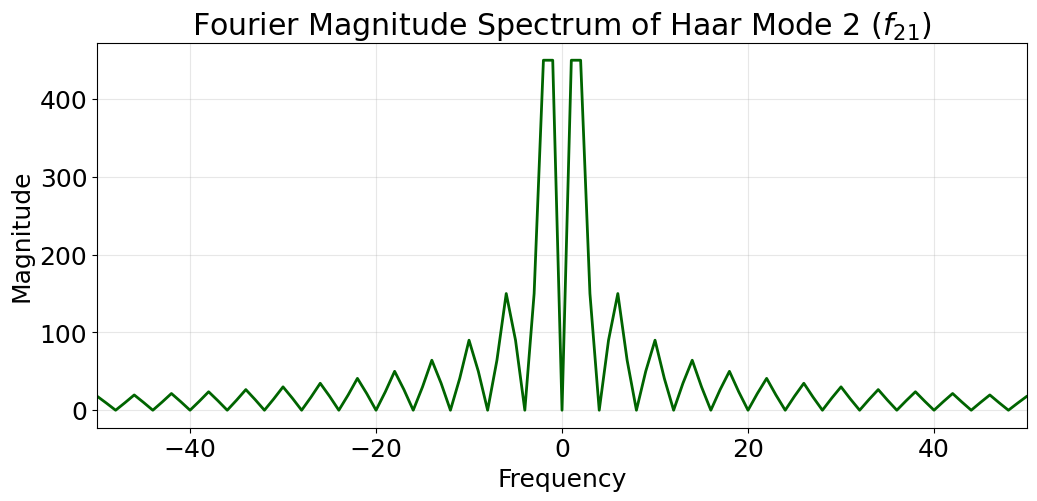

In [26]:
# Compute and plot the Fourier transform of Haar mode 2 (f21)
F_f21 = fft(f21)
F_f21_shifted = fftshift(F_f21)

plt.figure(figsize=(12,5))
plt.plot(freqs_shifted, np.abs(F_f21_shifted), color='darkgreen', linewidth=2)
plt.title('Fourier Magnitude Spectrum of Haar Mode 2 ($f_{21}$)')
plt.xlabel('Frequency')
plt.ylabel('Magnitude')
plt.grid(True, alpha=0.3)
plt.xlim(-50, 50)
plt.show()

## Fourier Analysis of Haar Mode 3 ($f_{22}$)

Finally, we analyze the frequency content of the third Haar wavelet ($f_{22}$) by computing its discrete Fourier transform (DFT). This reveals the highest-frequency content among the three modes.

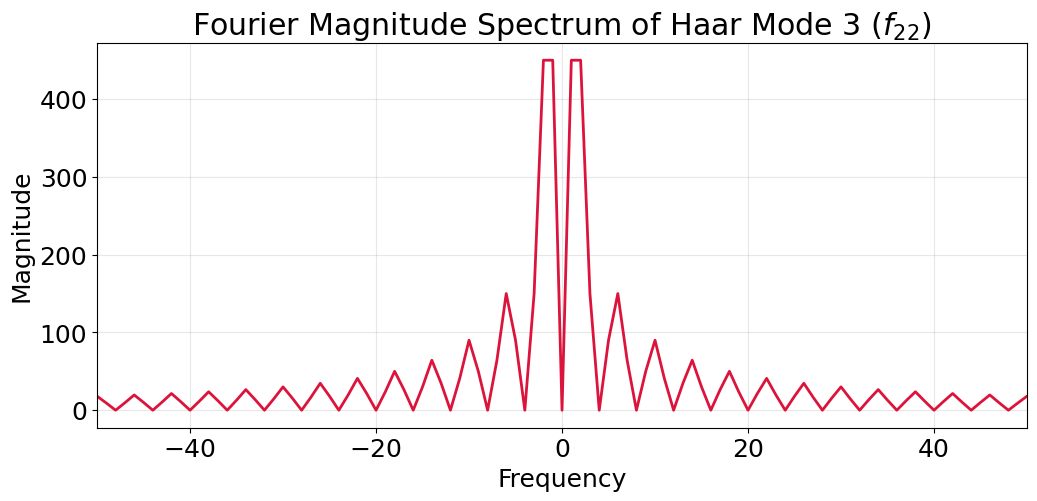

In [27]:
# Compute and plot the Fourier transform of Haar mode 3 (f22)
F_f22 = fft(f22)
F_f22_shifted = fftshift(F_f22)

plt.figure(figsize=(12,5))
plt.plot(freqs_shifted, np.abs(F_f22_shifted), color='crimson', linewidth=2)
plt.title('Fourier Magnitude Spectrum of Haar Mode 3 ($f_{22}$)')
plt.xlabel('Frequency')
plt.ylabel('Magnitude')
plt.grid(True, alpha=0.3)
plt.xlim(-50, 50)
plt.show()

### Visualizing Approximation and Detail Coefficients
The following cell visualizes the approximation and detail coefficients (horizontal, vertical, diagonal) from the first level of Haar wavelet decomposition for the image `DATA/dog.jpg`.

- **Approximation (cA):** Contains the low-frequency, smooth structure of the image (overall shapes and gradual changes).
- **Horizontal Detail (cH):** Captures high-frequency changes in the horizontal direction (vertical edges and transitions).
- **Vertical Detail (cV):** Captures high-frequency changes in the vertical direction (horizontal edges and transitions).
- **Diagonal Detail (cD):** Captures high-frequency changes along diagonals (corners, textures, and diagonal features).

Together, these coefficients allow you to analyze and reconstruct the image at different scales and orientations.

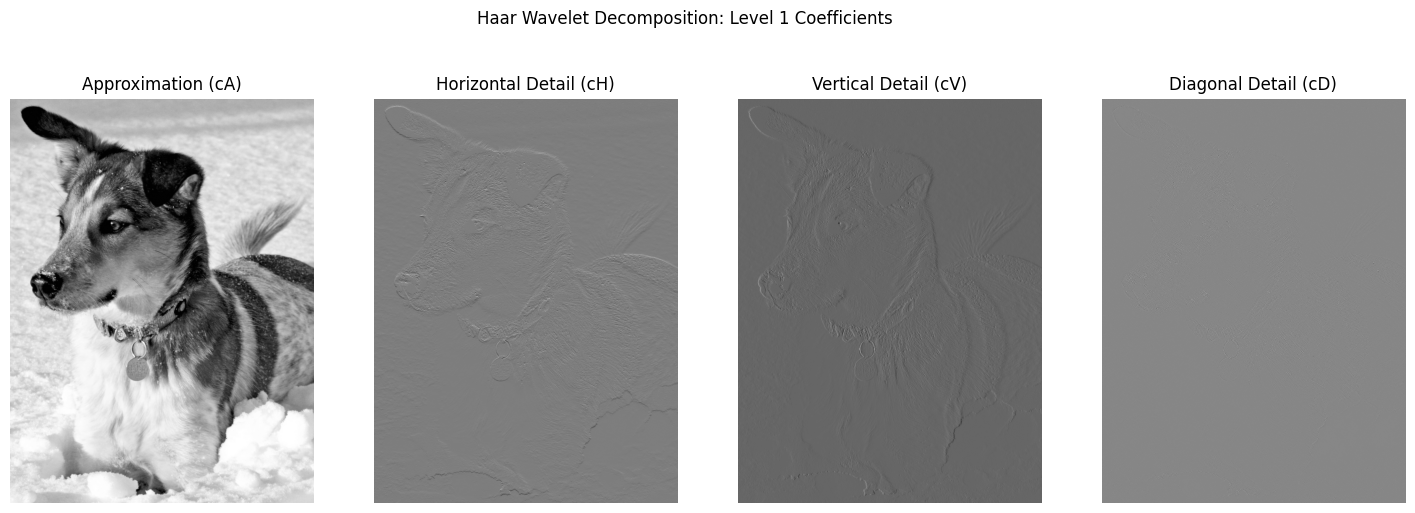

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.image import imread
import pywt
import os

# Load and convert image to grayscale
A = imread(os.path.join('..','DATA','dog.jpg'))
B = np.mean(A, -1)  # Convert RGB to grayscale
# Perform 1-level Haar wavelet decomposition
coeffs2 = pywt.dwt2(B, 'haar')
cA, (cH, cV, cD) = coeffs2
# Plot the coefficients
fig, axs = plt.subplots(1, 4, figsize=(18, 6))
axs[0].imshow(cA, cmap='gray')
axs[0].set_title('Approximation (cA)')
axs[0].axis('off')
axs[1].imshow(cH, cmap='gray')
axs[1].set_title('Horizontal Detail (cH)')
axs[1].axis('off')
axs[2].imshow(cV, cmap='gray')
axs[2].set_title('Vertical Detail (cV)')
axs[2].axis('off')
axs[3].imshow(cD, cmap='gray')
axs[3].set_title('Diagonal Detail (cD)')
axs[3].axis('off')
plt.suptitle('Haar Wavelet Decomposition: Level 1 Coefficients')
plt.show()

### Haar Wavelet Modes: Width, Height, and Localization

The plot below shows the first eight Haar wavelet modes ($f_{10}$, $f_{21}$, $f_{22}$, $f_{23}$, $f_{24}$, $f_{25}$, $f_{26}$, $f_{27}$) on $[0,1]$.

- **Width:** As the mode number increases, each wavelet becomes more localized (narrower support). Lower modes can be constructed with even wider support, potentially spanning the entire domain or more, depending on the application.
- **Height:** To keep the total energy (norm) of each wavelet equal to 1, the height increases as the width decreases. For a wavelet supported on width $w$, the height is $1/\sqrt{2w}$.
- **Localization:** Higher modes oscillate more rapidly and are localized in smaller intervals, capturing finer details.
- **Domain:** The interval $[0,1]$ is arbitrary; Haar wavelets can be defined on any interval. Lower modes with wider support capture coarser features, while higher modes with narrower support capture finer details.

This normalization ensures that all wavelets form an orthonormal basis, which is essential for efficient signal representation and reconstruction.

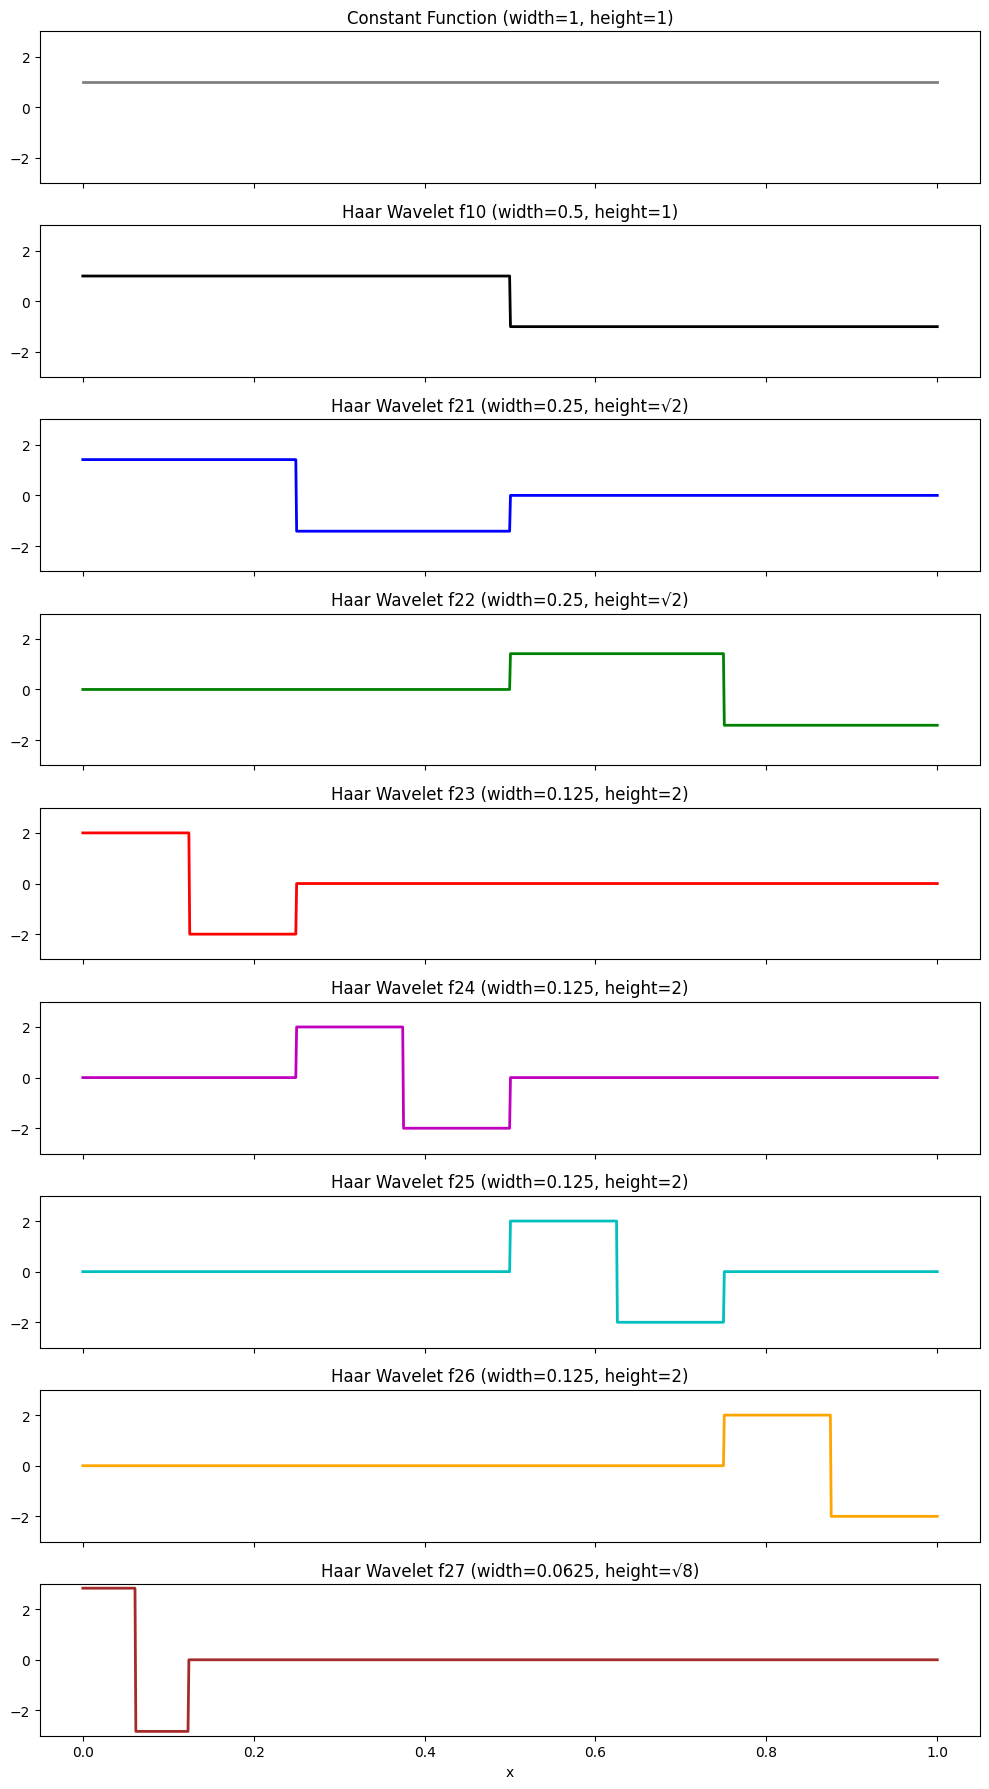

In [7]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(0, 1, 1000)
n = len(x)
n2 = n // 2
n4 = n // 4
n8 = n // 8
n16 = n // 16

# Example of a lower mode with wider support (spanning the whole interval)
f00 = np.ones_like(x)
f00[:n] = 1 / np.sqrt(1)  # Normalized constant function (not a wavelet, but shows the idea)

# First three Haar wavelets
f10 = np.zeros_like(x)
f10[:n2] = 1
f10[n2:] = -1
f10 = f10 * 1  # width=0.5, height=1
f21 = np.zeros_like(x)
f21[:n4] = 1
f21[n4:n2] = -1
f21 = f21 * np.sqrt(2)
f22 = np.zeros_like(x)
f22[n2:n2+n4] = 1
f22[n2+n4:] = -1
f22 = f22 * np.sqrt(2)

# Next five Haar wavelets (higher modes)
f23 = np.zeros_like(x)
f23[:n8] = 1
f23[n8:n4] = -1
f23 = f23 * np.sqrt(4)
f24 = np.zeros_like(x)
f24[n4:n4+n8] = 1
f24[n4+n8:n2] = -1
f24 = f24 * np.sqrt(4)
f25 = np.zeros_like(x)
f25[n2:n2+n8] = 1
f25[n2+n8:3*n4] = -1
f25 = f25 * np.sqrt(4)
f26 = np.zeros_like(x)
f26[3*n4:3*n4+n8] = 1
f26[3*n4+n8:] = -1
f26 = f26 * np.sqrt(4)
f27 = np.zeros_like(x)
f27[:n16] = 1
f27[n16:2*n16] = -1
f27 = f27 * np.sqrt(8)

fig, axs = plt.subplots(9, 1, figsize=(10, 18), sharex=True)
axs[0].plot(x, f00, color='gray', linewidth=2)
axs[0].set_title('Constant Function (width=1, height=1)')
axs[0].set_ylim(-3, 3)
axs[1].plot(x, f10, color='k', linewidth=2)
axs[1].set_title('Haar Wavelet f10 (width=0.5, height=1)')
axs[1].set_ylim(-3, 3)
axs[2].plot(x, f21, color='b', linewidth=2)
axs[2].set_title('Haar Wavelet f21 (width=0.25, height=√2)')
axs[2].set_ylim(-3, 3)
axs[3].plot(x, f22, color='g', linewidth=2)
axs[3].set_title('Haar Wavelet f22 (width=0.25, height=√2)')
axs[3].set_ylim(-3, 3)
axs[4].plot(x, f23, color='r', linewidth=2)
axs[4].set_title('Haar Wavelet f23 (width=0.125, height=2)')
axs[4].set_ylim(-3, 3)
axs[5].plot(x, f24, color='m', linewidth=2)
axs[5].set_title('Haar Wavelet f24 (width=0.125, height=2)')
axs[5].set_ylim(-3, 3)
axs[6].plot(x, f25, color='c', linewidth=2)
axs[6].set_title('Haar Wavelet f25 (width=0.125, height=2)')
axs[6].set_ylim(-3, 3)
axs[7].plot(x, f26, color='orange', linewidth=2)
axs[7].set_title('Haar Wavelet f26 (width=0.125, height=2)')
axs[7].set_ylim(-3, 3)
axs[8].plot(x, f27, color='brown', linewidth=2)
axs[8].set_title('Haar Wavelet f27 (width=0.0625, height=√8)')
axs[8].set_ylim(-3, 3)
plt.xlabel('x')
plt.tight_layout()
plt.show()

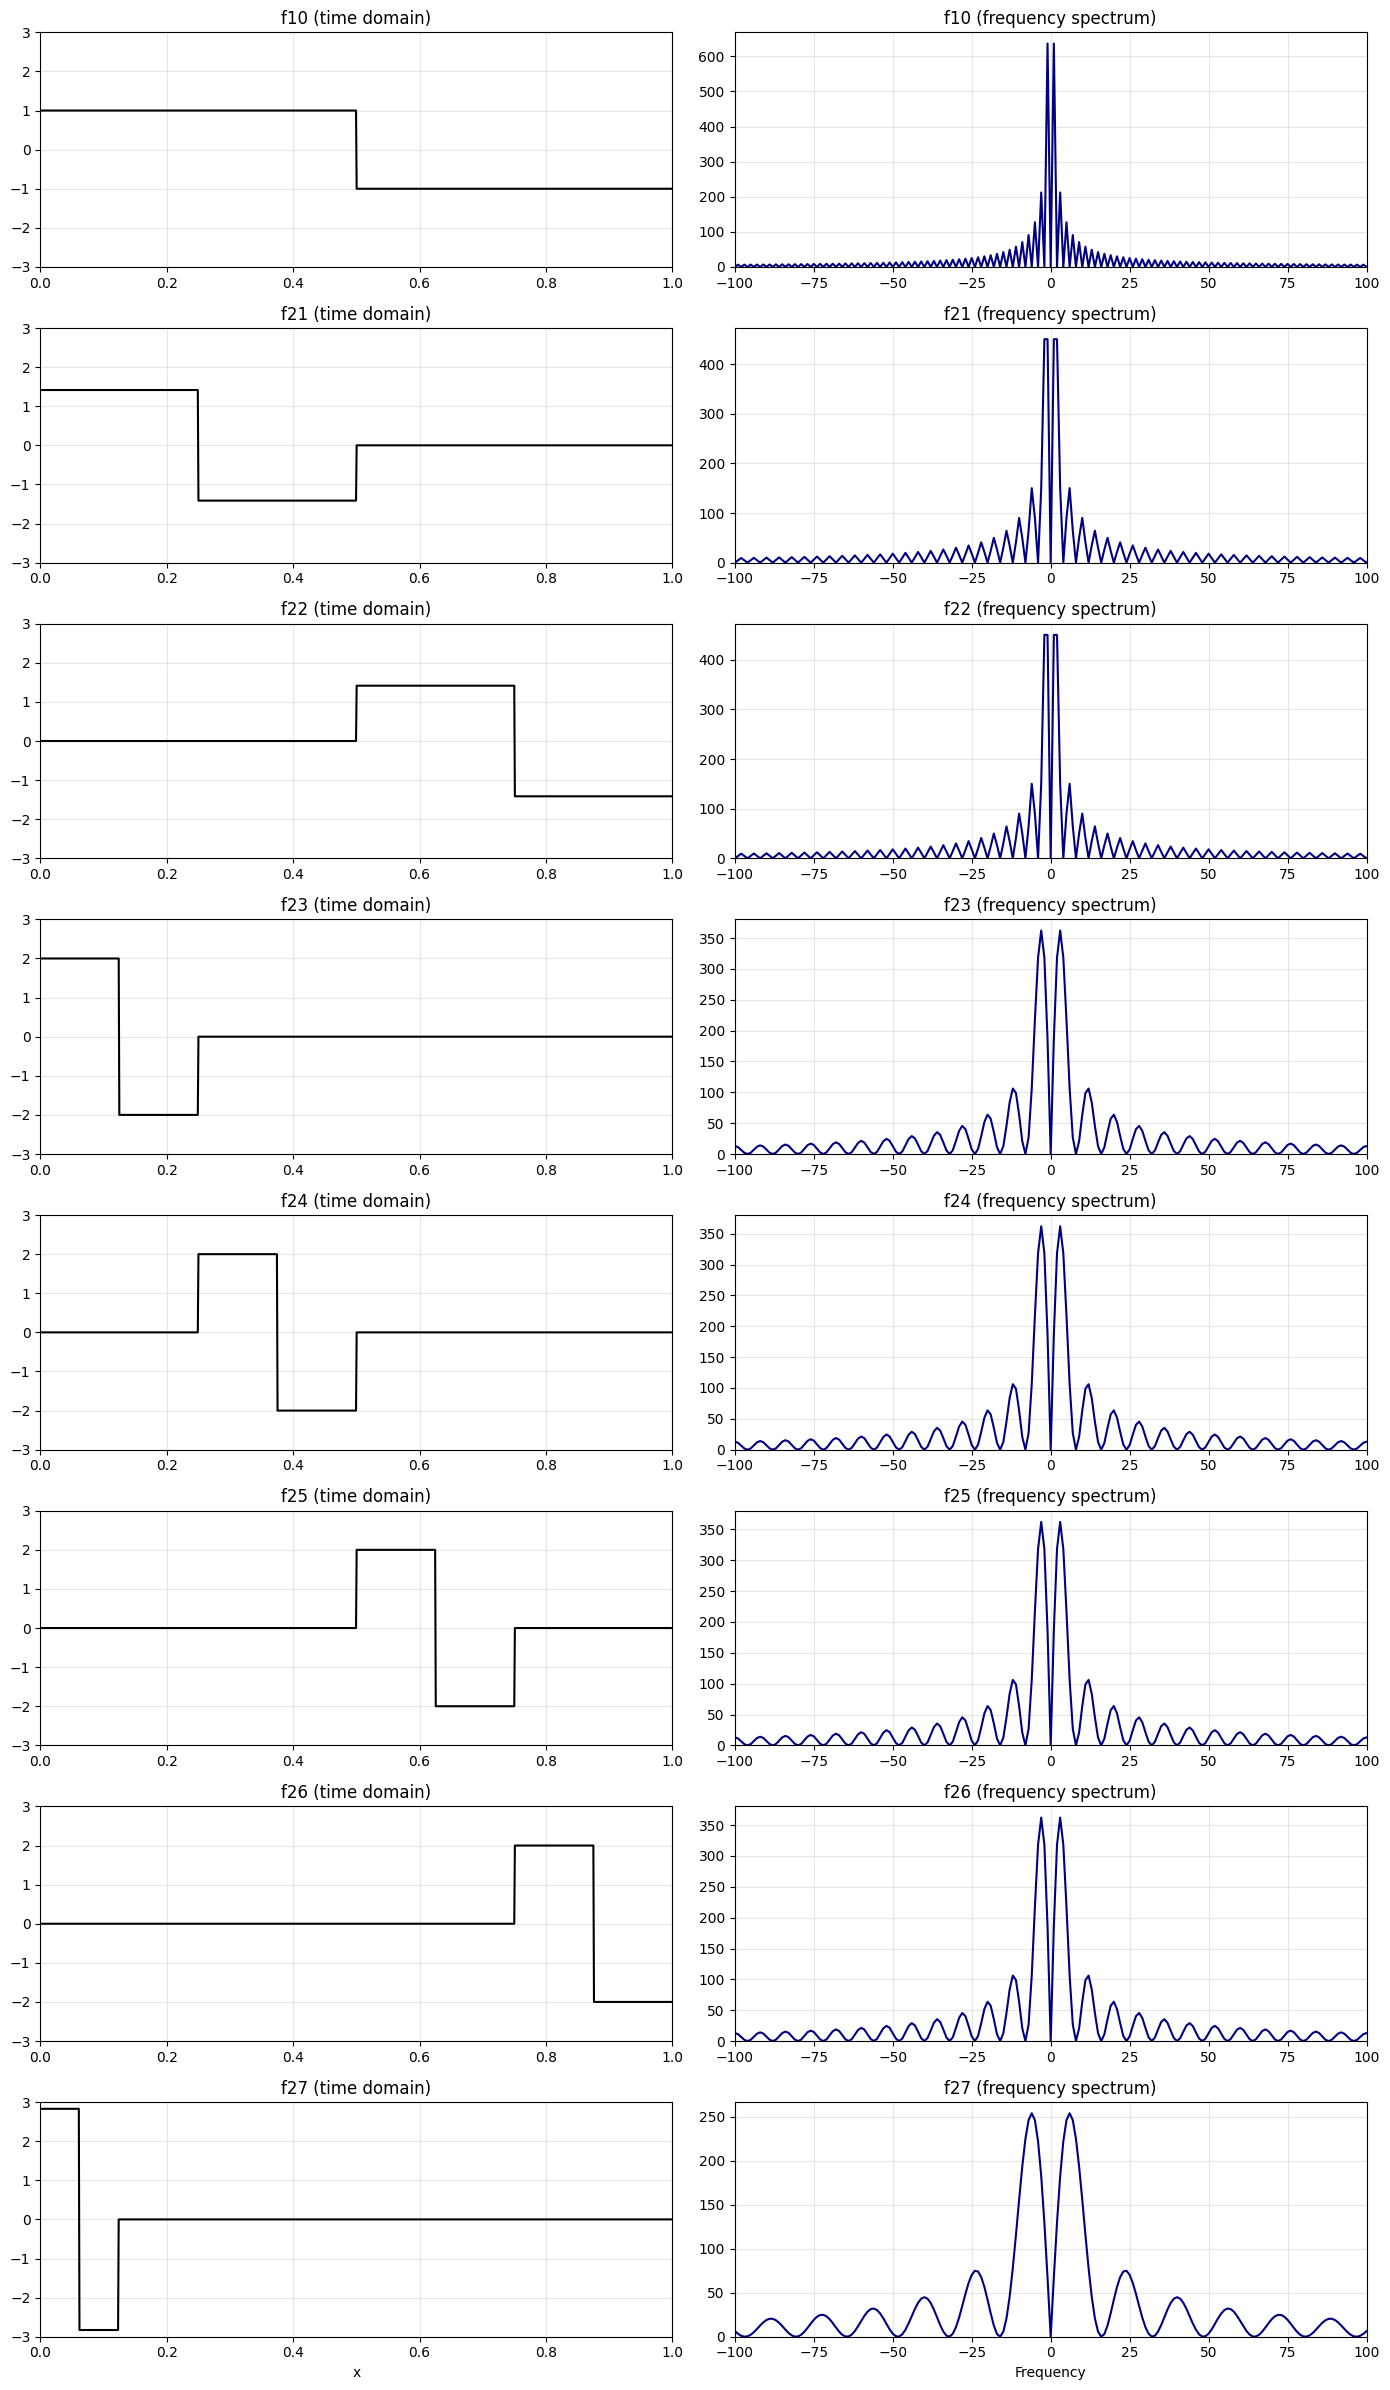

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import fft, fftfreq, fftshift

x = np.linspace(0, 1, 1000)
n = len(x)
n2 = n // 2
n4 = n // 4
n8 = n // 8
n16 = n // 16

# Define all 8 Haar wavelets
wavelets = []
# f10
f10 = np.zeros_like(x)
f10[:n2] = 1
f10[n2:] = -1
wavelets.append((f10, 'f10'))
# f21
f21 = np.zeros_like(x)
f21[:n4] = 1
f21[n4:n2] = -1
f21 = f21 * np.sqrt(2)
wavelets.append((f21, 'f21'))
# f22
f22 = np.zeros_like(x)
f22[n2:n2+n4] = 1
f22[n2+n4:] = -1
f22 = f22 * np.sqrt(2)
wavelets.append((f22, 'f22'))
# f23
f23 = np.zeros_like(x)
f23[:n8] = 1
f23[n8:n4] = -1
f23 = f23 * np.sqrt(4)
wavelets.append((f23, 'f23'))
# f24
f24 = np.zeros_like(x)
f24[n4:n4+n8] = 1
f24[n4+n8:n2] = -1
f24 = f24 * np.sqrt(4)
wavelets.append((f24, 'f24'))
# f25
f25 = np.zeros_like(x)
f25[n2:n2+n8] = 1
f25[n2+n8:3*n4] = -1
f25 = f25 * np.sqrt(4)
wavelets.append((f25, 'f25'))
# f26
f26 = np.zeros_like(x)
f26[3*n4:3*n4+n8] = 1
f26[3*n4+n8:] = -1
f26 = f26 * np.sqrt(4)
wavelets.append((f26, 'f26'))
# f27
f27 = np.zeros_like(x)
f27[:n16] = 1
f27[n16:2*n16] = -1
f27 = f27 * np.sqrt(8)
wavelets.append((f27, 'f27'))

fig, axs = plt.subplots(8, 2, figsize=(14, 24))

for i, (w, label) in enumerate(wavelets):
    # Time domain plot
    axs[i, 0].plot(x, w, color='k')
    axs[i, 0].set_title(f'{label} (time domain)')
    axs[i, 0].set_xlim(0, 1)
    axs[i, 0].set_ylim(-3, 3)
    axs[i, 0].grid(True, alpha=0.3)
    # Frequency domain plot
    W = fft(w)
    freqs = fftfreq(n, d=x[1]-x[0])
    W_shifted = fftshift(W)
    freqs_shifted = fftshift(freqs)
    axs[i, 1].plot(freqs_shifted, np.abs(W_shifted), color='navy')
    axs[i, 1].set_title(f'{label} (frequency spectrum)')
    axs[i, 1].set_xlim(-100, 100)
    axs[i, 1].set_ylim(0, None)
    axs[i, 1].grid(True, alpha=0.3)

axs[-1, 0].set_xlabel('x')
axs[-1, 1].set_xlabel('Frequency')
plt.tight_layout()
plt.show()

## Interpreting the Frequency Spectrum of Haar Wavelets

### Visual Summary
- **Lower mode Haar wavelets** (e.g., $f_{10}$) are wide and smooth, so their frequency spectrum is concentrated at low frequencies. They capture the coarse, smooth features of a signal.
- **Higher mode Haar wavelets** (e.g., $f_{27}$) are narrow and oscillate rapidly, so their frequency spectrum spreads out to higher frequencies. They capture fine details and sharp transitions.

| Haar Wavelet | Time Domain | Frequency Spectrum |
|--------------|-------------|-------------------|
| $f_{10}$     | Wide, 1 jump | Peaks at low frequencies |
| $f_{21}$, $f_{22}$ | Narrower, 2 jumps | Peaks at higher frequencies |
| $f_{23}$–$f_{27}$ | Very narrow, many jumps | Peaks at even higher frequencies |

**Visualization:**
- In the plots, the left column shows each wavelet in the time domain.
- The right column shows the magnitude of its Fourier transform (frequency spectrum).
- As the mode increases, the spectrum shifts outward, showing more energy at higher frequencies.

---
### Mathematical Explanation
- The **Fourier transform** of a function $f(x)$ decomposes it into a sum of complex exponentials (sines and cosines) of different frequencies:
  $$
  \hat{f}(k) = \int_{-\infty}^{\infty} f(x) e^{-2\pi i k x} dx
  $$
- The **magnitude** $|\hat{f}(k)|$ tells us how much of frequency $k$ is present in $f(x)$.
- **Haar wavelets** are piecewise-constant, localized functions. Their sharp jumps introduce high-frequency components in their spectrum.
- **Lower modes** (wider wavelets) have fewer jumps, so their spectrum is concentrated at low $|k|$.
- **Higher modes** (narrower wavelets) have more jumps and are more localized, so their spectrum spreads out to higher $|k|$.
- This is a manifestation of the **uncertainty principle**: a function that is localized in time (narrow) must be spread out in frequency, and vice versa.

**Summary:**
- Lower Haar modes capture low-frequency (smooth) content.
- Higher Haar modes capture high-frequency (detailed) content.
- The frequency spectrum visually and mathematically confirms this property.